# ASMSA v2 &mdash; Train

&#8592; [Tune](03-tune.ipynb) &nbsp;|&nbsp; [PLUMED export](05-plumed.ipynb) &#8594;

| | |
|---|---|
| **What it does** | Train the autoencoder with proper validation and model selection, then judge whether the latent space is actually usable as a collective variable. |
| **Typical runtime** | minutes on CPU for a small system |
| **Needs** | <code>features.pt</code>, <code>split.npz</code>; optionally <code>tuning.json</code> |
| **Produces** | a model checkpoint, and the diagnostics to trust or reject it |

---

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import mdtraj as md

import asmsa_v2 as asmsa
from asmsa_v2.viz import use_asmsa_style

use_asmsa_style()
project = asmsa.Project.load('run')
asmsa.set_seed(0)

bundle = torch.load(project.features_file, weights_only=False)
Xs = bundle['features']
blocks = bundle['feature_blocks']
scaler = asmsa.FeatureScaler.load(project.scaler_file)
sp = np.load(project.split_file, allow_pickle=False)

print(f'features {tuple(Xs.shape)}   '
      f"split train/val/test = {sp['train'].size}/{sp['val'].size}/{sp['test'].size}")

features (50001, 596)   split train/val/test = 35001/7500/7500


## 1. Configuration

If [03-tune](03-tune.ipynb) has run, its winner is used. Otherwise sensible defaults
are chosen and reported, so this notebook works standalone.

In [2]:
EPOCHS = 300          # an upper bound; early stopping decides when to stop

if project.tuning_file.exists():
    from asmsa_v2.tune import TuningResult
    tuning = TuningResult.load(project.tuning_file)
    model_cfg, train_cfg = tuning.to_configs(epochs=EPOCHS)
    print(f'using the best of {len(tuning.trials)} tuned trials '
          f'(objective {tuning.objective}, score {tuning.best.score:.4f})')
else:
    model_cfg = asmsa.ModelConfig(latent_dim=project.latent_dim)
    train_cfg = asmsa.TrainConfig(epochs=EPOCHS, batch_size=128,
                                  latent_reg='mmd', lam_latent=10.0)
    print('no tuning results found; using defaults '
          '(run 03-tune.ipynb to do better)')

# Settings this notebook owns regardless of tuning:
train_cfg.epochs = EPOCHS
train_cfg.time_lagged = bool(project.time_lag)
train_cfg.monitor = 'val_loss_recon'
train_cfg.restore_best = True
train_cfg.seed = 0
train_cfg.progress = True

for k in ('epochs', 'batch_size', 'lr_ae', 'lr_d', 'latent_reg', 'lam_latent',
          'recon_loss', 'adv_mode', 'time_lagged', 'monitor'):
    print(f'  {k:<16} {getattr(train_cfg, k)}')

using the best of 2 tuned trials (objective kl, score 1.5519)
  epochs           300
  batch_size       128
  lr_ae            0.0004806404295331634
  lr_d             0.00011441366694389211
  latent_reg       mmd
  lam_latent       0.1979991282401945
  recon_loss       huber
  adv_mode         joint
  time_lagged      False
  monitor          val_loss_recon


## 2. Datasets

Two details that look pedantic and are not:

- the **validation** loader must not shuffle and must not drop its last partial batch.
  A shuffling validation loader makes the metric depend on the batch partition, so the
  same weights score differently on each pass and "best epoch" becomes partly noise.
  `eval_loader()` sets both correctly.
- with `time_lag > 0` the reconstruction target is the frame `time_lag` steps **ahead**,
  which makes the latent encode the *slow* degrees of freedom rather than whichever
  carry the most instantaneous variance (Wehmeyer & No&eacute;, JCP 148, 241703 (2018)).
  This usually produces better enhanced-sampling CVs.

In [3]:
if project.time_lag:
    train_ds = asmsa.make_time_lagged_dataset({'complex': Xs[sp['train']]},
                                              lag=project.time_lag)
    val_ds = asmsa.make_time_lagged_dataset({'complex': Xs[sp['val']]},
                                            lag=project.time_lag)
    print(f'time-lagged objective, lag = {project.time_lag} frames')
else:
    train_ds = asmsa.MultiMolDataset({'complex': Xs[sp['train']]})
    val_ds = asmsa.MultiMolDataset({'complex': Xs[sp['val']]})
    print('instantaneous reconstruction objective')

train_loader = train_ds.loader(batch_size=train_cfg.batch_size)
val_loader = val_ds.eval_loader(batch_size=512)
print(f'{len(train_loader)} training batches/epoch, '
      f'{len(val_loader)} validation batches')

instantaneous reconstruction objective
273 training batches/epoch, 15 validation batches


## 3. Train

| Callback | Role |
|---|---|
| `EarlyStopping` | Stops when validation reconstruction stops improving. Monitoring a *training* loss cannot detect overfitting, and under an adversarial objective it is not even monotone. |
| `ModelCheckpoint` | Writes the best weights to disk, with optimizer state, so training can be resumed. |
| `LiveLossPlot` | Train and validation curves on shared axes, updated in place. |
| `LatentSnapshot` | Records the latent every few epochs. The most informative single diagnostic for an adversarial autoencoder. |

Best weights are restored at the end (`restore_best=True`), so the model you keep is the
one from the best validation epoch, not whatever the last epoch happened to produce.

130,559 parameters, latent_dim=2
device: cuda


epoch 1/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 2/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 3/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 4/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 5/300:   0%|          | 0/273 [00:00<?, ?batch/s]

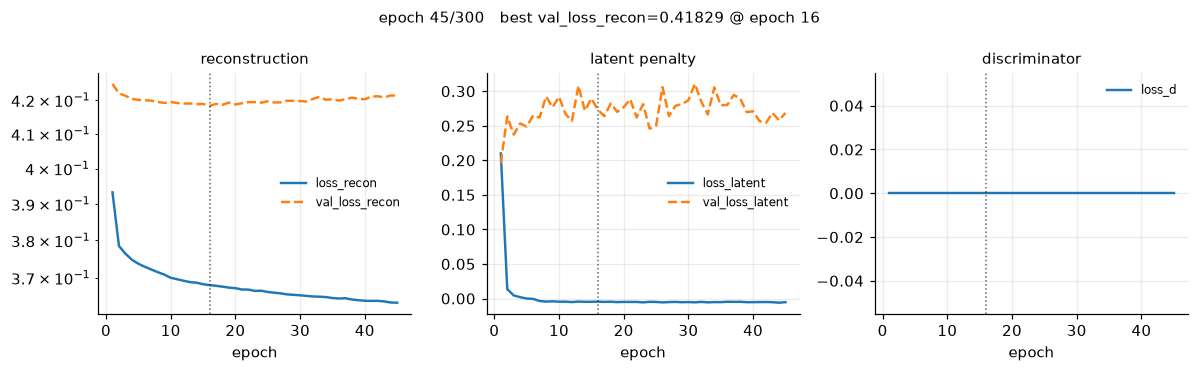

epoch 6/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 7/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 8/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 9/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 10/300:   0%|          | 0/273 [00:00<?, ?batch/s]

...

epoch 43/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 44/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 45/300:   0%|          | 0/273 [00:00<?, ?batch/s]

epoch 46/300:   0%|          | 0/273 [00:00<?, ?batch/s]

EarlyStopping: val_loss_recon did not improve for 30 epochs (best 0.41829 at epoch 15); stopping at epoch 45.

stopped after 46 epochs; best val_loss_recon = 0.41829 at epoch 16


In [4]:
model = asmsa.AAE(
    feature_dims=train_ds.feature_dims,
    latent_dim=model_cfg.latent_dim,
    encoder_widths=model_cfg.encoder_widths,
    decoder_widths=model_cfg.decoder_widths,
    disc_widths=model_cfg.disc_widths,
    activation=model_cfg.activation,
    batchnorm=model_cfg.batchnorm,
    spectral_norm_disc=model_cfg.spectral_norm_disc,
)
n_params = sum(p.numel() for p in model.parameters())
print(f'{n_params:,} parameters, latent_dim={model_cfg.latent_dim}')

snapshots = asmsa.LatentSnapshot({'complex': Xs}, every=10, max_frames=4000)
callbacks = [
    asmsa.EarlyStopping(patience=30, monitor='val_loss_recon'),
    asmsa.ModelCheckpoint(project.checkpoint_file, monitor='val_loss_recon'),
    asmsa.CsvLogger(project.dir('models') / f'{project.model_name}-history.csv'),
    asmsa.LiveLossPlot(every=5),
    snapshots,
]

trainer = asmsa.Trainer(model, prior=project.make_prior(), config=train_cfg,
                        callbacks=callbacks)
print('device:', trainer.device)
history = trainer.fit(train_loader, val_loader)
print(f'\nstopped after {len(history["loss_recon"])} epochs; '
      f'best val_loss_recon = {trainer.best_score:.5f} at epoch {trainer.best_epoch + 1}')

### Training curves

**What to look for:**

- *reconstruction* &mdash; train and validation both falling, and the gap between them
  not widening. A validation curve that turns up while the training curve keeps falling
  is overfitting; early stopping should have caught it (the dotted line marks the epoch
  whose weights were kept).
- *latent penalty* &mdash; should settle, not drift.
- *discriminator* (adversarial runs only) &mdash; should hover near the dotted
  `2 log 2 = 1.386` line, which is where a critic that cannot distinguish the latent from
  the prior sits. Falling far below means the critic is winning and the encoder has given
  up; climbing far above means the opposite.

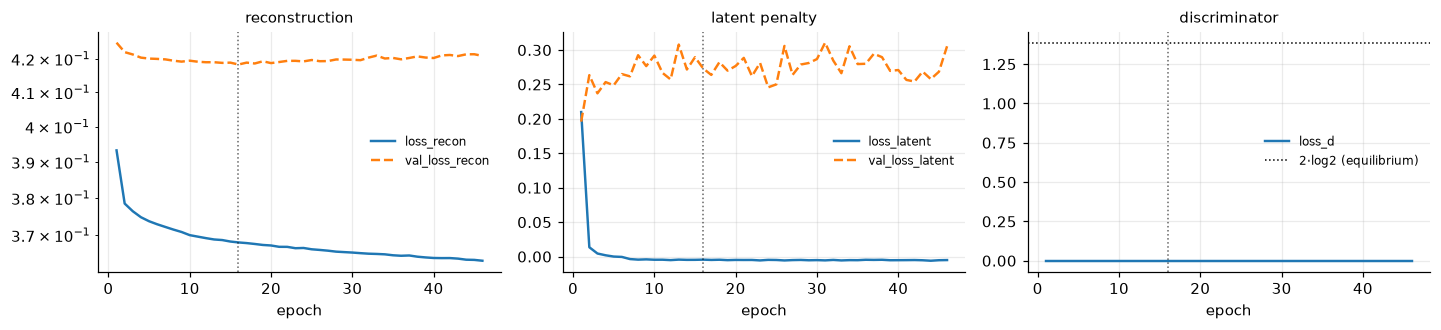

In [5]:
asmsa.viz.training_curves(history, best_epoch=trainer.best_epoch)
plt.tight_layout(); plt.show()

### How the latent organized itself

**What to look for:** a shape that stabilizes. A latent still rearranging in the last
panels has not converged; one that collapses to a line or a few dots has failed, and no
amount of further training will fix it &mdash; lower `lam_latent`, or switch
`latent_reg` to `mmd`/`sliced`.

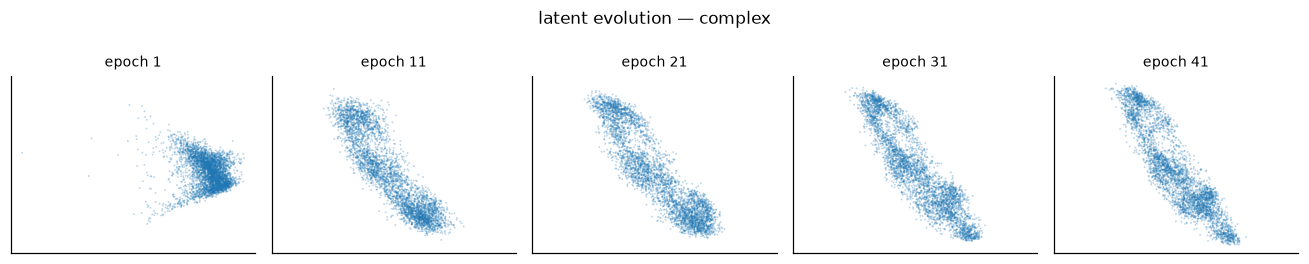

In [18]:
fig = snapshots.plot(ncols=6)
plt.show()

## 4. Is this model usable?

Scored on the **test split**, which neither training nor model selection ever saw.

| Metric | Meaning | If `poor` |
|---|---|---|
| reconstruction | fraction of feature variance left unexplained | widen the network, train longer, or lower `lam_latent` |
| prior match | KL between prior and latent | raise `lam_latent`, or try `latent_reg='mmd'` |
| slow dynamics (VAMP-2) | how much of the slow subspace the latent resolves | set `time_lag > 0` in [01-setup](01-setup.ipynb) and retrain &mdash; this is the fix that matters for CVs |
| usable spread | is the latent genuinely 2-D, or collapsed to a line | lower `lam_latent`; a collapsed latent cannot drive metadynamics and [05-plumed](05-plumed.ipynb) will refuse it |

In [7]:
X_test = Xs[sp['test']]
z_test = trainer.encode_all({'complex': X_test})['complex'].numpy()
x_recon = trainer.reconstruct_all({'complex': X_test})['complex'].numpy()

VAMP_LAG = 20   # frames
report = asmsa.evaluate_latent(
    z_test, x=X_test.numpy(), x_recon=x_recon,
    prior=project.make_prior(), vamp_lag=VAMP_LAG,
    in_time_order=(project.split_strategy == 'chronological'),
)
report

metric,value,verdict,meaning
reconstruction (relative MSE),1.130,poor,fraction of standardized feature variance left unexplained; 1.0 = no better than predicting the mean
"prior match (KL, nats)",1.600,poor,k-NN KL between prior and latent samples; v1 treated < 0.5-0.7 as acceptable
slow dynamics (VAMP-2 @ lag 20),1.493 / 3,poor,"how much of the slow subspace the latent resolves; higher is better, max is 1 + latent_dim"
usable spread (effective dim),1.48 / 2,ok,participation ratio of latent variance; well below latent_dim means the latent collapsed to a lower-dimensional manifold


## 5. What did the latent space learn?

Encode **every** frame (not just the test split) and colour by interpretable
observables. This is the interpretation step: if a basin corresponds to a particular
ligand pose or a particular radius of gyration, the colouring shows it.

**What to look for:** colour varying *smoothly and systematically* across the latent
plane. A property that looks like random noise over the latent is one the model did not
capture.

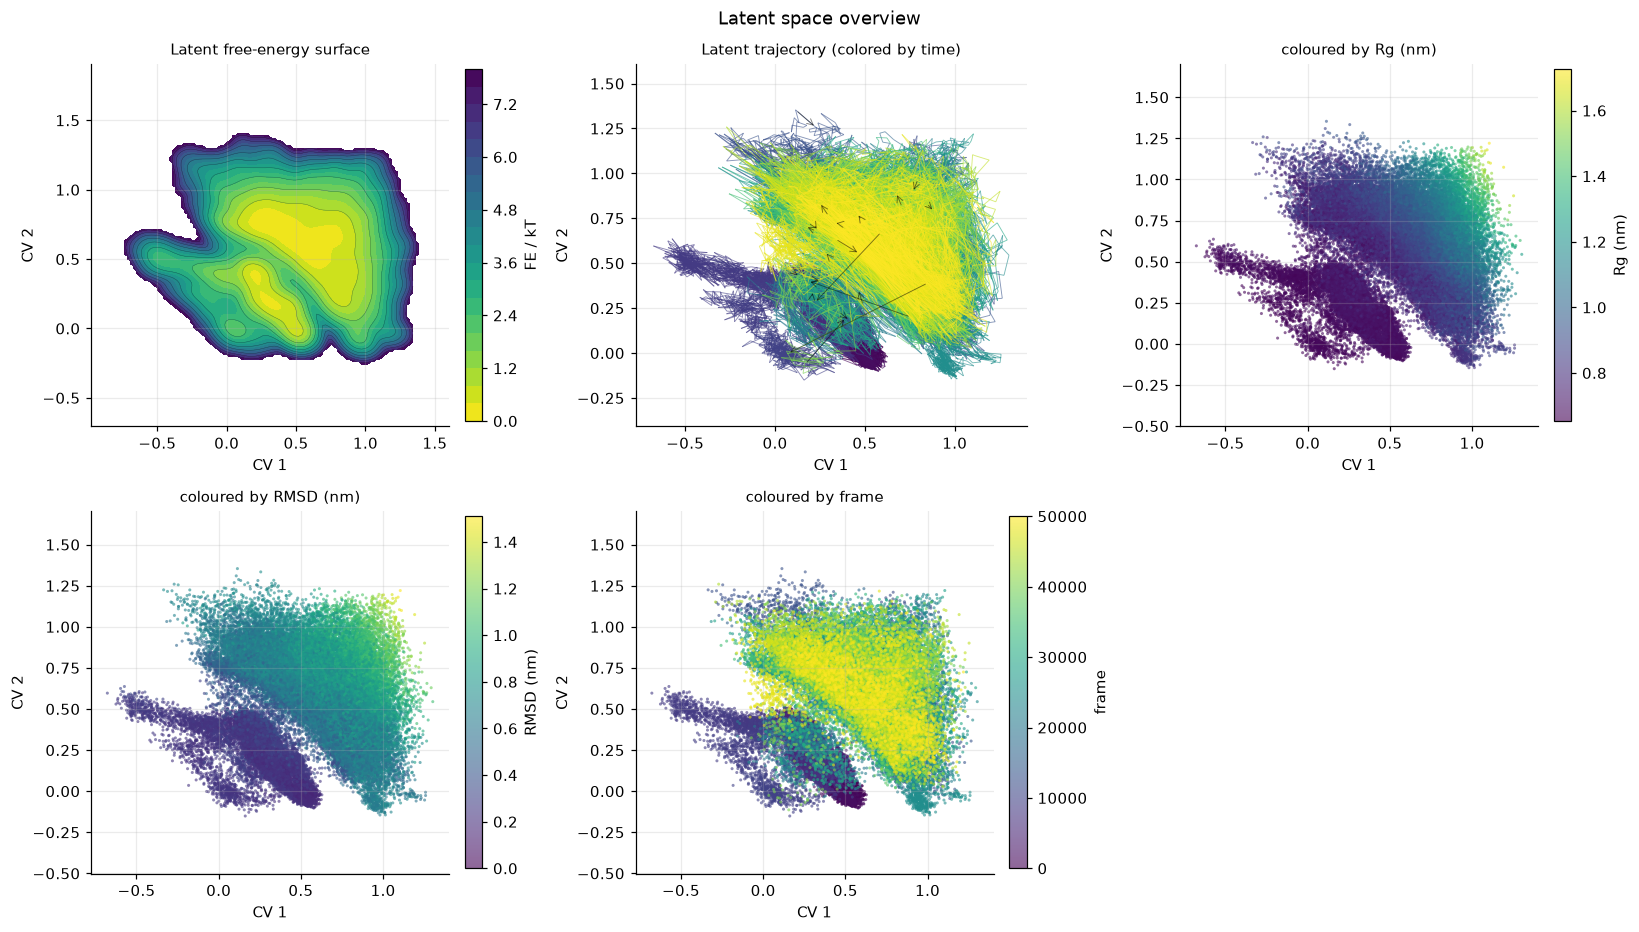

In [8]:
z_all = trainer.encode_all({'complex': Xs})['complex'].numpy()
np.save(project.dir('models') / f'latent-{project.model_name}.npy', z_all)

props_file = project.dir('datasets') / 'properties.npz'
if props_file.exists():
    props = {k: v for k, v in np.load(props_file).items()}
else:
    traj = md.load(str(project.traj_path), top=str(project.conf_path))
    components = {k: traj.top.select(v) for k, v in (project.components or {}).items()}
    props = asmsa.viz.standard_properties(traj, components or None)

fig = asmsa.viz.latent_overview(
    z_all, properties=props,
    in_time_order=True,
)
plt.show()

### Are these CVs slow?

The question that decides whether the latent is useful for enhanced sampling.
Metadynamics has to push the system along coordinates that are *hard* to cross; a
latent that tracks fast, freely-relaxing motion will not help.

**What to look for:** implied timescales that rise and then **plateau**. Only the
plateau value is physically meaningful. Timescales that keep tracking the diagonal
`lag` line are at the resolution limit &mdash; the model resolves nothing slower than
the lag you tested.

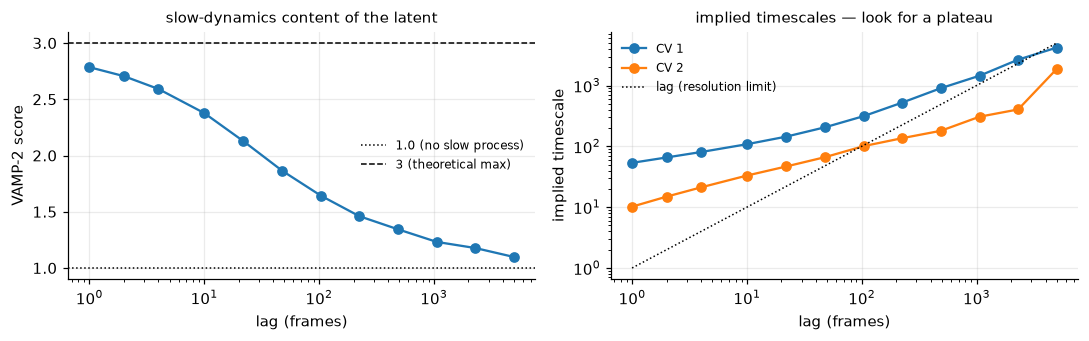

In [9]:
asmsa.viz.vamp_scan_plot(z_all, dt=1.0)
plt.tight_layout(); plt.show()

### Which features are reconstructed badly?

**What to look for:** the histogram mass well below 1.0. A feature at or above 1.0 is
reconstructed no better than by predicting its mean &mdash; the model is ignoring it. A
whole block above 1.0 means that block is not represented in the latent at all, which
matters if it is the inter-component block carrying the binding pose.

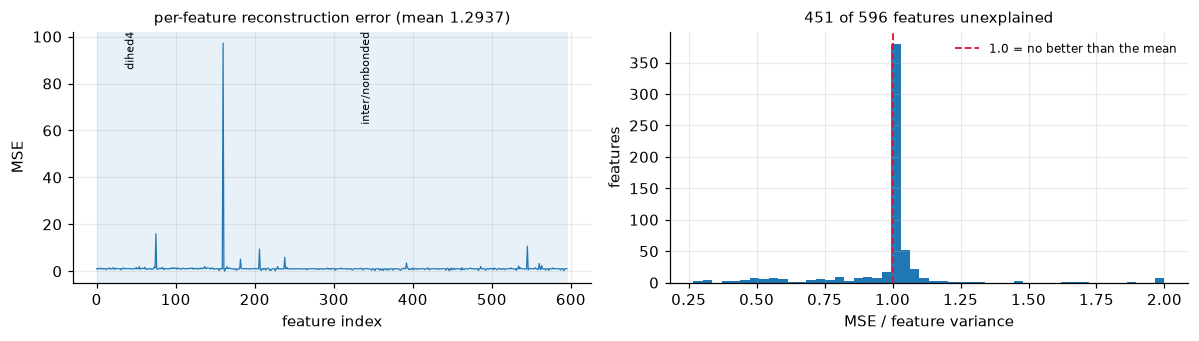

In [10]:
asmsa.viz.reconstruction_report(X_test.numpy(), x_recon, blocks=blocks)
plt.tight_layout(); plt.show()

## 6. Save

`ModelCheckpoint` already wrote the best weights during training. This re-saves the
restored model together with everything [05-plumed](05-plumed.ipynb) needs to rebuild
the exact same transform chain.

In [11]:
trainer.save_checkpoint(
    project.checkpoint_file,
    model_config=model_cfg.to_dict(),
    scaler_method=scaler.method,
    n_features=int(Xs.shape[1]),
    latent_dim=int(model_cfg.latent_dim),
    quality=dict(recon_relative=report.recon_relative,
                 kl_prior=report.kl_prior,
                 vamp2=report.vamp2,
                 effective_dim=report.effective_dim),
)
print(f'saved {project.checkpoint_file.relative_to(project.root)}')
project

saved 03-models/norm.pt


root,/home/tedeschg/prj/ASMSA_v2/notebooks/run
conf,/home/tedeschg/prj/unfolding-data/trpcage_npt400_nH.pdb
traj,/home/tedeschg/prj/unfolding-data/trpcage_ds_nH.xtc
components,(single molecule)
model,norm / prior=uniform / latent_dim=2
split,"chronological (0.7, 0.15, 0.15)"
md,100.0 ns @ 300.0 K
✓,01 prepare (features)
✓,01 prepare (scaler)
✓,01 prepare (split)
✓,02 tune


---
## Optional: compare objectives side by side

The honest way to choose between the latent regularizers, and between instantaneous and
time-lagged reconstruction, for *your* system. Each variant is trained from the same
seed on the same split, then scored on the same held-out test frames.

This costs several training runs. Set `RUN_COMPARISON = True` to do it.

In [14]:
RUN_COMPARISON = True

variants = {
    'adversarial (classic AAE)': dict(latent_reg='adversarial', lam_latent=1.0),
    'adversarial + R1':          dict(latent_reg='adversarial', lam_latent=1.0,
                                      r1_gamma=1.0),
    'MMD (WAE)':                 dict(latent_reg='mmd', lam_latent=10.0),
    'sliced Wasserstein':        dict(latent_reg='sliced', lam_latent=10.0),
    'plain autoencoder':         dict(latent_reg='none'),
}

if RUN_COMPARISON:
    import warnings
    rows, latents = [], {}
    for label, overrides in variants.items():
        cfg = asmsa.TrainConfig(**{**train_cfg.to_dict(),
                                   **overrides,
                                   'epochs': 80, 'progress': False, 'seed': 0})
        asmsa.set_seed(0)
        m = asmsa.AAE(feature_dims=train_ds.feature_dims,
                      latent_dim=model_cfg.latent_dim)
        t = asmsa.Trainer(m, project.make_prior(), cfg)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            t.fit(train_loader, val_loader)
        zt = t.encode_all({'complex': X_test})['complex'].numpy()
        r = asmsa.evaluate_latent(
            zt, x=X_test.numpy(),
            x_recon=t.reconstruct_all({'complex': X_test})['complex'].numpy(),
            prior=project.make_prior(), vamp_lag=VAMP_LAG)
        latents[label] = t.encode_all({'complex': Xs})['complex'].numpy()
        rows.append((label, r))
        print(f'{label:<28} recon {r.recon_relative:.3f}  KL {r.kl_prior:.3f}  '
              f'VAMP-2 {r.vamp2:.3f}  eff.dim {r.effective_dim:.2f}')

adversarial (classic AAE)    recon 1.129  KL 2.707  VAMP-2 1.471  eff.dim 1.46


KeyboardInterrupt: 

In [ ]:
if RUN_COMPARISON:
    fig, axes = plt.subplots(1, len(latents), figsize=(4.0 * len(latents), 4.0))
    for ax, (label, z) in zip(np.atleast_1d(axes), latents.items()):
        asmsa.viz.free_energy_surface(z, ax=ax, max_FE=6.0)
        ax.set_title(label, fontsize=9)
        asmsa.viz.latent_axes(ax)
    plt.tight_layout(); plt.show()
    print('A latent collapsed to a line or a blob has low effective dimension and',
          'cannot drive metadynamics, however good its reconstruction loss looks.')

---

&#8592; [Tune](03-tune.ipynb) &nbsp;|&nbsp; **Next: [PLUMED export](05-plumed.ipynb)** &#8594;